# Partial differential equations 3: Laplace and Poisson

*Learning path: partial differential equations, part 3 of 3.* [Index](README.md) · Previous: [Waves on a string](02-waves-on-a-string.ipynb)

Heat a metal plate along one edge, keep the other edges cool, and wait. The temperature settles into a pattern that no
longer changes. The same pattern describes the voltage between electrodes, the slow flow of groundwater, the shape of
a soap film stretched on a wire frame and the flow of air around a wing. All are solutions of **Laplace's equation**

$$u_{xx} + u_{yy} = 0,$$

which Pierre-Simon Laplace used around 1780 for the gravity of planets. Add a source, such as heat produced inside
the plate or electric charge, and it becomes **Poisson's equation** $u_{xx} + u_{yy} = f$ (Siméon Denis Poisson, 1813).

These are the equations of things that have stopped changing: the steady states of heat flow in two dimensions. There
is no time; instead the values on the whole edge decide the inside all at once.

**Who this is for.** Students who have done [the heat equation](01-the-heat-equation.ipynb); partial derivatives
([multivariable calculus](../multivariable/README.md)) help.

**What you will be able to do afterwards:**

1. explain Laplace's equation as "every point is the average of its neighbours";
2. solve it on a rectangle with `laplace`, with different values on each edge, and show the result with `pdeplot`;
3. solve it by hand with Jacobi relaxation, and know why faster methods exist;
4. check a solution against the exact series solution;
5. solve Poisson's equation with `poisson` for a membrane under pressure.

Plan about 50 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. A plate in equilibrium

On a square grid with spacing $h$, the second differences in $x$ and $y$ give the **five-point formula**

$$u_{xx} + u_{yy} \approx \frac{u_{\text{left}} + u_{\text{right}} + u_{\text{below}} + u_{\text{above}} - 4u}{h^2}.$$

Setting it to 0 says: **the temperature at each point is the average of its four neighbours**. In equilibrium no
point can be hotter than all its neighbours (it would cool down) or colder than all of them. That has a striking
consequence, the **maximum principle**: the highest and lowest values are always on the edge.

`laplace(g, x, a, b, y, c, d)` solves Laplace's equation on the rectangle $a \le x \le b$, $c \le y \le d$ with
$u = g(x, y)$ on the edge. A last record sets single edges: `left` and `right` (expressions in $y$), `bottom` and
`top` (in $x$). Keep the top edge of a unit square at 100 degrees and the other three at 0:

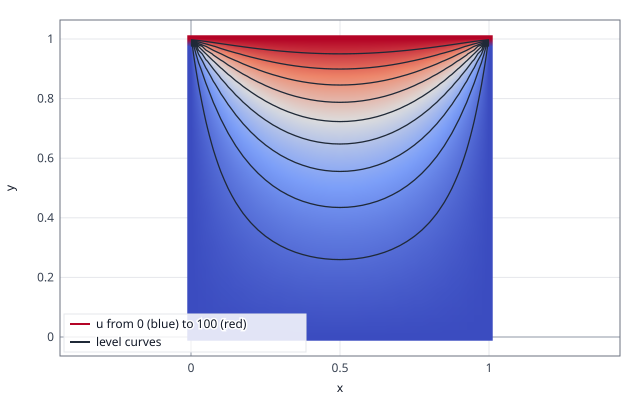

> pdeplot: u(x, y) as colors, blue low and red high, with level curves on top.

In [1]:
s = laplace(0, x, 0, 1, y, 0, 1, {top: 100});
pdeplot(s)

The result is a record with the grid `x`, `y` and the values `u`, where `u(j, i)` is the temperature at
$(x_i, y_j)$; the grid has 41 points each way, so the centre is `u(21, 21)`:

In [2]:
U = s.u;
eval(U(21, 21), 5)

25.000

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Exactly 25. Here is why. Turn the square a quarter turn at a time: the four problems "edge $k$ at 100, the others at 0"
have the same centre temperature, and adding all four gives the problem "all edges at 100", whose solution is 100
everywhere. So each has centre value $100/4$. This is **superposition**: sums of solutions are solutions.

`pdeplot(s, "surface")` shows the same solution as a landscape:

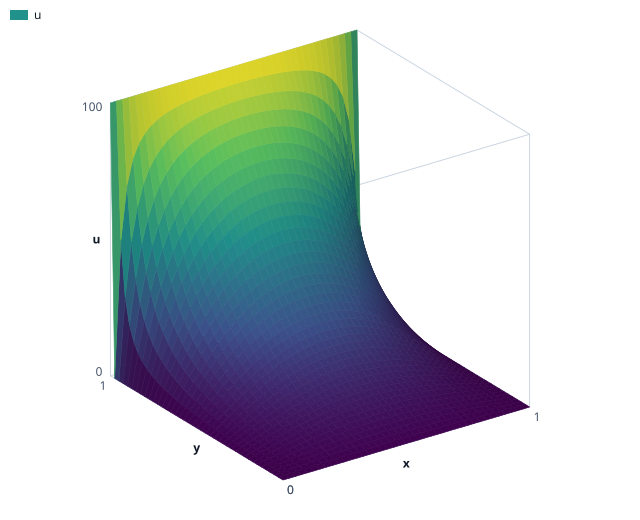

> pdeplot: u as a surface over the (x, y) plane.

In [3]:
pdeplot(s, "surface")

**Try this.** Keep the top at 100 and the left edge at 50, the rest at 0. Predict the centre temperature with
superposition, then check.

## 2. The exact solution by separation of variables

Look for solutions of the form $X(x)\,Y(y)$. Laplace's equation gives $X''/X = -Y''/Y$, a constant. With $X = 0$ at
$x = 0$ and $x = 1$, $X = \sin(m\pi x)$ and then $Y = \sinh(m\pi y)$, which vanishes at $y = 0$. Matching the top edge
$u = 100$ with a Fourier sine series, as in lesson 1, gives

$$u(x, y) = \sum_{m \text{ odd}} \frac{400}{m\pi}\, \sin(m\pi x)\, \frac{\sinh(m\pi y)}{\sinh(m\pi)}.$$

At the centre, five terms:

In [4]:
f = 0;
for m = 1:2:9
  f = f + 400/(m*pi) * sin(m*pi/2) * sinh(m*pi/2)/sinh(m*pi);
end
eval(f, 5)

25.000

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Separation of variables works for rectangles, discs and a few other shapes. The grid method works for any shape and
any edge values, which is why engineers use it.

For a smooth edge function the grid solution is very accurate. If the edge values come from a function that already
solves Laplace's equation, such as $e^x \cos y$, the solution must be that function. Check it at $(x, y) = (3/4, 1/4)$,
which is grid point `u(11, 31)`:

In [5]:
s = laplace(exp(x)*cos(y), x, 0, 1, y, 0, 1);
U = s.u;
eval(U(11, 31), 6)
eval(exp(3/4)*cos(1/4), 6)

2.05120

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

2.05119

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**Try this.** Check that $e^x \cos y$ is **harmonic** (solves Laplace's equation) with `laplacian(exp(x)*cos(y), [x y])`.
Which of $x^2 + y^2$, $x^2 - y^2$, $xy$ and $x^3 - 3xy^2$ are harmonic too?

## 3. Relaxation by hand

How does a computer find the averages, when every value depends on its neighbours? The simplest method, due to Carl
Jacobi (1845), is to guess and then repeatedly replace every inside value by the average of its four neighbours. Try it
on a 7 by 7 grid (5 by 5 inside), top row at 100, starting from 0 inside, and watch the centre:

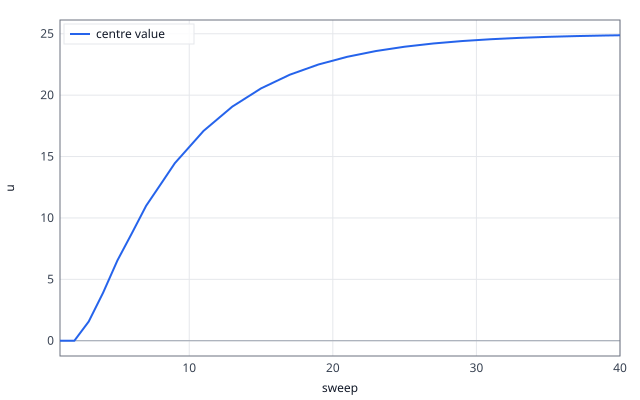

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
N = 6;
V = zeros(N + 1, N + 1);
for i = 1:N + 1
  V(N + 1, i) = 100;
end
centre = zeros(1, 40);
for sweep = 1:40
  W = V;
  for j = 2:N
    for i = 2:N
      W(j, i) = (V(j, i - 1) + V(j, i + 1) + V(j - 1, i) + V(j + 1, i))/4;
    end
  end
  V = W;
  centre(sweep) = V(4, 4);
end
labels(legend(plot(1:40, centre), "centre value"), "sweep", "u")

The centre creeps towards 25: heat "diffuses" in from the edge, sweep after sweep. In fact Jacobi's method *is* the
explicit heat equation scheme of lesson 1, run until nothing changes. That is also its weakness: information moves
only one grid point per sweep, and the error shrinks by a factor $1 - O(h^2)$ per sweep, so a grid twice as fine needs
four times as many sweeps.

`laplace` uses **successive over-relaxation**: it uses new values as soon as they are computed, and overshoots each
average by a factor $\omega$ close to 2. With the best $\omega$ the number of sweeps grows only like $1/h$ instead of
$1/h^2$. David Young found the best $\omega$ in 1950, for exactly this problem; its note reports the sweeps and
$\omega$.

**Try this.** Change the number of sweeps to 100. How close to 25 does the centre get? Is the limit exactly 25 on this
coarse grid? (Use superposition again.)

## 4. Poisson's equation: a membrane under pressure

Stretch a rubber membrane over a square frame and blow gently from below: the pressure lifts it. Its height $u$ solves
**Poisson's equation** $u_{xx} + u_{yy} = -p$, with $u = 0$ on the frame, where $p$ is the pressure divided by the
tension. The same equation gives the twisting stiffness of a steel bar with that cross-section (Saint-Venant's
torsion problem), the flow of a liquid through a square pipe, and the voltage in a box filled with charge.

`poisson(f, g, x, a, b, y, c, d)` solves $u_{xx} + u_{yy} = f$ with $u = g$ on the edge. Take $p = 1$:

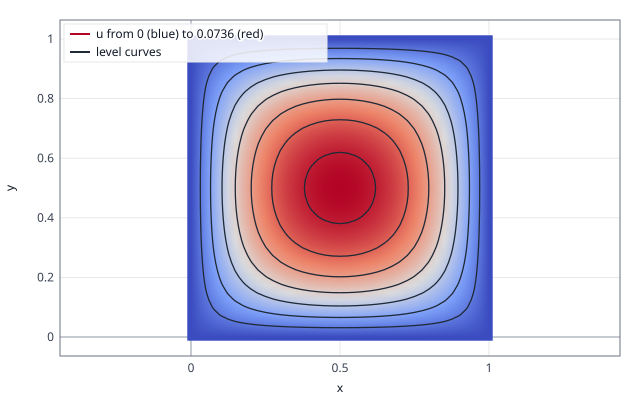

> pdeplot: u(x, y) as colors, blue low and red high, with level curves on top.

In [7]:
s = poisson(-1, 0, x, 0, 1, y, 0, 1);
pdeplot(s)

The level curves are almost circles near the middle and become squares near the frame. The highest point:

In [8]:
U = s.u;
eval(U(21, 21), 5)

0.073635

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The exact value, from a double Fourier series, is $0.0736713\ldots$. A grid twice as fine (`{n: 80}`) gets four times
closer, the same $h^2$ behaviour as in lesson 1.

Stretch the frame into a long strip, 10 by 1. Far from the short ends the membrane no longer feels them and becomes
the one-dimensional problem $u'' = -1$ across the strip, $u = y(1 - y)/2$, whose highest value is $1/8$:

In [9]:
s = poisson(-1, 0, x, 0, 10, y, 0, 1, {n: 200});
U = s.u;
eval(U(11, 101), 5)

0.12500

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**Try this.** A 2 by 1 frame: is its highest point closer to the square's $0.0737$ or to the strip's $0.125$? Use
`poisson(-1, 0, x, 0, 2, y, 0, 1)` and look at `u(11, 21)`.

## 5. A hot spot

A source concentrated near one point, such as a small heater in a plate whose edges are kept at 0, makes a peak.
Poisson's equation with $f = -100\,e^{-200((x - 0.3)^2 + (y - 0.6)^2)}$:

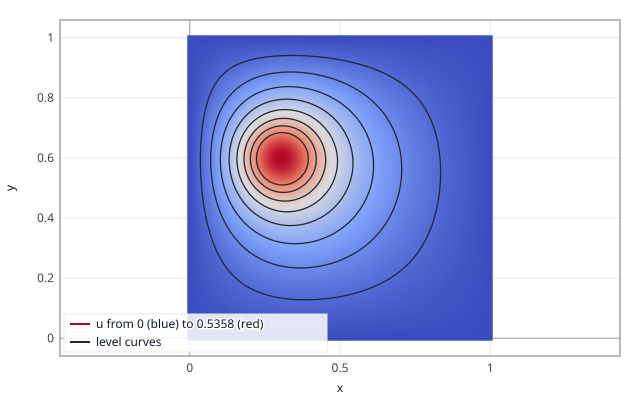

> pdeplot: u(x, y) as colors, blue low and red high, with level curves on top.

In [10]:
s = poisson(-100*exp(-200*((x - 0.3)^2 + (y - 0.6)^2)), 0, x, 0, 1, y, 0, 1, {n: 60});
pdeplot(s)

Close to the heater the level curves are circles, as for a point source in an infinite plate, where
$u = -\tfrac{Q}{2\pi}\ln r$: the temperature falls off like the logarithm of the distance. Near the cold edges they
bend to follow the edges. The same picture shows the voltage around a charged wire in a grounded box, which is how
the equation is used to design cables and microchips.

**Try this.** Move the heater towards a corner, to $(0.15, 0.15)$. Does the peak get higher or lower? Why?

## Summary

* Laplace's equation $u_{xx} + u_{yy} = 0$: every point is the average of its neighbours; it gives steady states of
  heat, voltages, potential flow and soap films. The highest and lowest values lie on the edge.
* `laplace(g, x, a, b, y, c, d)` and `poisson(f, g, ...)` solve on a rectangle with the five-point formula; options
  set single edges and the grid. `u(j, i)` is the value at $(x_i, y_j)$.
* Superposition and symmetry give exact answers, such as 25 at the centre.
* Separation of variables gives series solutions on rectangles.
* Jacobi relaxation is the heat equation run to the end; over-relaxation is much faster.

This completes the path. The [differential equations](../differential-equations/README.md) path covers ordinary
differential equations; [random processes](../random-processes/README.md) shows where the heat equation meets
Brownian motion.

## Exercises

1. **Three hot edges.** The top, left and right edges of a square are at 100 and the bottom at 0. What is the centre
   temperature? Check with `laplace`.
2. **A warm wall.** The top edge follows $u = 100\sin(\pi x)$, the others are 0. The exact solution is the single term
   $100\sin(\pi x)\sinh(\pi y)/\sinh(\pi)$. Compare it with `laplace` at the centre.
3. **Maximum principle.** Solve `laplace(x^2 - y^2, x, -1, 1, y, -1, 1)` and find `max(max(u))` and `min(min(u))`.
   Where are they?
4. **A heated plate.** A plate produces heat evenly ($f = -1$) and its edges are at 0. How does its highest temperature
   change when the square is twice as big, $0 \le x, y \le 2$? Explain with a change of scale.
5. **Two electrodes.** The left edge of a square box is at voltage 1, the right edge at $-1$, top and bottom at 0.
   What is the voltage along the middle line $x = 1/2$? Check with `laplace` and look at the map.

## Hints and answers

* **Section 1, Try this.** $25 + 50/4 = 37.5$.
* **Section 2, Try this.** $e^x\cos y$ gives 0. $x^2 - y^2$, $xy$ and $x^3 - 3xy^2$ are harmonic (they are the real and
  imaginary parts of $z^2$ and $z^3$); $x^2 + y^2$ is not, its Laplacian is 4.
* **Section 3, Try this.** After 100 sweeps the centre is 25.00 to two decimals. The limit is exactly 25 even on the
  coarse grid: the quarter-turn argument works for the grid equations too.
* **Section 4, Try this.** About $0.114$: in between, but closer to the strip.
* **Section 5, Try this.** Lower: the cold edges are closer and carry the heat away.
* **Exercise 1.** $3 \cdot 25 = 75$.
* **Exercise 2.** $100\sinh(\pi/2)/\sinh(\pi) \approx 19.93$; `laplace` gives about $19.94$.
* **Exercise 3.** The largest value 1 is at $(\pm 1, 0)$ and the smallest $-1$ at $(0, \pm 1)$, all on the edge;
  inside, $u = x^2 - y^2$ is a saddle with no maximum or minimum.
* **Exercise 4.** Four times as high: with $x = 2X$, $y = 2Y$ the equation becomes $u_{XX} + u_{YY} = -4$.
* **Exercise 5.** 0 everywhere on the middle line: reflecting the box in that line swaps the electrodes and flips the
  sign of the solution, so the values on the line equal minus themselves. The level curves crowd together at the
  corners, where 1 or $-1$ meets 0: the electric field is strongest there.

## Sources

1. P.-S. Laplace, "Théorie des attractions des sphéroïdes et de la figure des planètes", *Mémoires de l'Académie
   Royale des Sciences de Paris* (1782, published 1785), 113–196.
2. S. D. Poisson, "Remarques sur une équation qui se présente dans la théorie des attractions des sphéroïdes",
   *Nouveau Bulletin de la Société Philomatique de Paris* 3 (1813), 388–392.
3. D. M. Young, "Iterative methods for solving partial difference equations of elliptic type", PhD thesis, Harvard
   University (1950).
4. W. A. Strauss, *Partial Differential Equations: An Introduction*, 2nd ed., Wiley (2008), chapter 6.
5. S. P. Timoshenko and J. N. Goodier, *Theory of Elasticity*, 3rd ed., McGraw–Hill (1970), chapter 10 (torsion and
   the membrane analogy).